In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [7]:
path = r"C:\Users\Amandi Jayasinghe\Downloads\sentiment+labelled+sentences\sentiment labelled sentences"

amazon = pd.read_csv(path + r"\amazon_cells_labelled.txt",
                     sep="\t", header=None, names=["text", "sentiment"])

imdb = pd.read_csv(path + r"\imdb_labelled.txt",
                   sep="\t", header=None, names=["text", "sentiment"])

yelp = pd.read_csv(path + r"\yelp_labelled.txt",
                   sep="\t", header=None, names=["text", "sentiment"])

df = pd.concat([amazon, imdb, yelp], ignore_index=True)

df.head()

,text,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


- 0 means negative and 1 means positive

##### preprocessing

###### Convert text to lowercase

In [8]:
df["clean_text"] = df["text"].str.lower()

df[["text", "clean_text"]].head()

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.","good case, excellent value."
2,Great for the jawbone.,great for the jawbone.
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great.


###### Remove punctuation and unnecessary characters

In [9]:
df["clean_text"] = df["clean_text"].str.replace(
    r"[^a-z0-9\s]", " ", regex=True
)

df[["text", "clean_text"]].head()

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great


###### Remove extra whitespace

In [10]:
df["clean_text"] = df["clean_text"].str.replace(
    r"\s+", " ", regex=True
).str.strip()

df[["text", "clean_text"]].head()

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great


##### Explore the Text Data

###### Display positive and negative reviews

In [11]:
# Display 5 positive reviews
print("Positive Reviews:")
display(df[df["sentiment"] == 1][["text", "sentiment"]].head())

# Display 5 negative reviews
print("Negative Reviews:")
display(df[df["sentiment"] == 0][["text", "sentiment"]].head())

Positive Reviews:


,text,sentiment
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
4,The mic is great.,1
7,If you are Razr owner...you must have this!,1
10,And the sound quality is great.,1


Negative Reviews:


,text,sentiment
0,So there is no way for me to plug it in here i...,0
3,Tied to charger for conversations lasting more...,0
5,I have to jiggle the plug to get it to line up...,0
6,If you have several dozen or several hundred c...,0
8,"Needless to say, I wasted my money.",0


###### Identify Frequently Occurring Words

In [12]:
from collections import Counter

# Combine all cleaned reviews into one text
all_text = " ".join(df["clean_text"])

# Split into individual words
words = all_text.split()

# Count word frequencies
word_counts = Counter(words)

# Display 10 most common words
word_counts.most_common(10)

[('the', 1953),
 ('and', 1138),
 ('i', 1037),
 ('a', 889),
 ('it', 789),
 ('is', 754),
 ('to', 670),
 ('this', 643),
 ('of', 624),
 ('was', 571)]

###### Compare Positive and Negative Reviews

In [13]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Separate positive and negative reviews
positive_text = " ".join(
    df[df["sentiment"] == 1]["clean_text"]
)

negative_text = " ".join(
    df[df["sentiment"] == 0]["clean_text"]
)

# Remove common stop words
positive_words = [
    word for word in positive_text.split()
    if word not in ENGLISH_STOP_WORDS
]

negative_words = [
    word for word in negative_text.split()
    if word not in ENGLISH_STOP_WORDS
]

# Display word frequencies
print("Top 10 Positive Words:")
print(Counter(positive_words).most_common(10))

print("\nTop 10 Negative Words:")
print(Counter(negative_words).most_common(10))

Top 10 Positive Words:
[('great', 193), ('good', 173), ('s', 140), ('film', 91), ('phone', 88), ('movie', 87), ('t', 72), ('really', 60), ('food', 60), ('best', 59)]

Top 10 Negative Words:
[('t', 209), ('s', 113), ('1', 108), ('bad', 96), ('movie', 95), ('0', 94), ('phone', 80), ('film', 72), ('just', 69), ('like', 67)]


- 10 most common words in each sentiment category, excluding common stop words.
- Words like phone, film, and movie appear in both categories because they describe the review topic rather than the sentiment.
- s, t, 1, and 0 are mostly leftover fragments from punctuation removal or numbers.Exclude single character tokens when creating our BOW.

##### Split the Dataset

- 80% Training data , 20% Testing data

In [14]:
from sklearn.model_selection import train_test_split

# Input features and target labels
X = df["clean_text"]
y = df["sentiment"]

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2198
Testing samples: 550


##### BOW

- cannot directly understand text, so we convert words into numerical .
- Each number represents how many times a word appears in the sentence.

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

# Create Bag of Words vectorizer
vectorizer = CountVectorizer(stop_words="english")

# Convert training text into numerical features
X_train_bow = vectorizer.fit_transform(X_train)

# Convert testing text using same vocabulary
X_test_bow = vectorizer.transform(X_test)

print("Training BoW shape:", X_train_bow.shape)
print("Testing BoW shape:", X_test_bow.shape)

Training BoW shape: (2198, 4263)
Testing BoW shape: (550, 4263)


##### Train the model

In [16]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model using Bag of Words features
model.fit(X_train_bow, y_train)

print("Model trained successfully!")

Model trained successfully!


##### Model Performance

In [17]:
# Predict sentiment for testing data
y_pred = model.predict(X_test_bow)

# Display first 10 predictions
print("Predicted:", y_pred[:10])
print("Actual:   ", y_test.values[:10])

Predicted: [0 1 0 1 1 0 0 1 0 1]
Actual:    [0 0 0 1 1 0 1 1 1 1]


###### Calculate Accuracy, Precision, Recall and F1-score

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.7891
Precision: 0.8182
Recall   : 0.7473
F1-score : 0.7811


###### Confusion Matrix

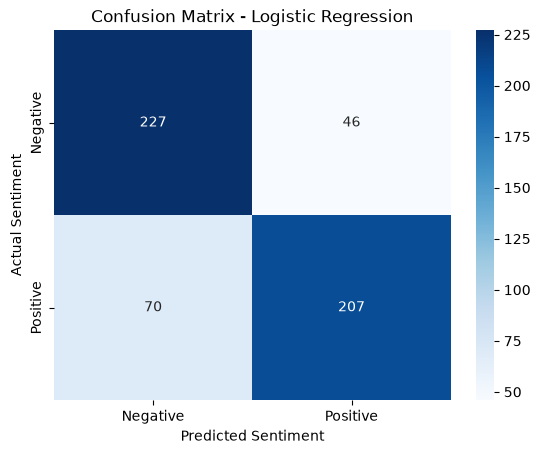

In [19]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

##### Test the Model with a New Sentence

In [20]:
import re

# Enter a new sentence
new_sentence = "This movie was absolutely amazing!"

# Apply the same preprocessing
clean_sentence = new_sentence.lower()
clean_sentence = re.sub(r"[^a-z0-9\s]", " ", clean_sentence)
clean_sentence = re.sub(r"\s+", " ", clean_sentence).strip()

# Convert sentence to Bag of Words
new_bow = vectorizer.transform([clean_sentence])

# Predict sentiment
prediction = model.predict(new_bow)

# Display result
if prediction[0] == 1:
    print("Positive Sentiment")
else:
    print("Negative Sentimen")

Positive Sentiment


#### Neural Network

In [1]:
%pip install tensorflow

  Using cached tensorflow-2.22.0rc1-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.85.1-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached keras_nightly-3.16.0.dev2026111703-py3-none-any.whl.metadata (6.6 kB)
  Using cached h5py-3.15.1-cp314-cp314-win_amd64.whl.metadata (3.1 kB)
  Using cached ml_dtypes-0.7.0-cp314-cp314-win_amd64.whl.metadata (11 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)


In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

###### Text Vectorization

In [21]:
max_words = 10000
sequence_length = 100

text_vectorizer = layers.TextVectorization(
    max_tokens=max_words,
    output_mode="int",
    output_sequence_length=sequence_length
)

text_vectorizer.adapt(X_train)

print("Text vectorization completed!")

   2198/Unknown 42s 19ms/step
Text vectorization completed!


###### Deep Learning Model

In [22]:
model = keras.Sequential([
    keras.Input(shape=(1,), dtype=tf.string),

    text_vectorizer,

    layers.Embedding(
        input_dim=max_words,
        output_dim=64
    ),

    layers.GlobalAveragePooling1D(),

    layers.Dense(32, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ text_vectorization_2                 │ (None, 100)                 │               0 │
│ (TextVectorization)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ embedding (Embedding)                │ (None, 100, 64)             │         640,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 642,113 (2.45 MB)

 Trainable params: 642,113 (2.45 MB)

 Non-trainable params: 0 (0.00 B)

###### Compile the Model

In [23]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


###### Train the Neural Network

In [26]:
import tensorflow as tf

# Convert text into TensorFlow string tensors
X_train_dl = tf.constant(
    X_train.fillna("").astype(str).tolist(),
    dtype=tf.string
)

X_train_dl = tf.reshape(X_train_dl, (-1, 1))

# Convert labels into TensorFlow numeric tensors
y_train_dl = tf.constant(
    y_train.tolist(),
    dtype=tf.float32
)

# Check data types
print("Text dtype:", X_train_dl.dtype)
print("Labels dtype:", y_train_dl.dtype)

# Train the model
history = model.fit(
    X_train_dl,
    y_train_dl,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Text dtype: <dtype: 'string'>
Labels dtype: <dtype: 'float32'>
Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - accuracy: 0.4875 - loss: 0.6940 - val_accuracy: 0.5250 - val_loss: 0.6923
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.4926 - loss: 0.6933 - val_accuracy: 0.4795 - val_loss: 0.6938
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.4989 - loss: 0.6934 - val_accuracy: 0.4795 - val_loss: 0.6936
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5085 - loss: 0.6926 - val_accuracy: 0.4795 - val_loss: 0.6945
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5341 - loss: 0.6912 - val_accuracy: 0.4795 - val_loss: 0.6935
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5512 - loss: 0.6890 - val_accuracy: 0.4795 - val_loss: 0.6911
Epoch 7/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5575 - loss: 0.6865 - val_accuracy: 0.5909 - val_loss: 0.6848
Epoch 8/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/s

In [27]:
# Prepare testing data
X_test_dl = tf.constant(
    X_test.fillna("").astype(str).tolist(),
    dtype=tf.string
)

X_test_dl = tf.reshape(X_test_dl, (-1, 1))

y_test_dl = tf.constant(
    y_test.tolist(),
    dtype=tf.float32
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(
    X_test_dl,
    y_test_dl
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6436 - loss: 0.6465
Test Loss: 0.6465
Test Accuracy: 64.36 %


In [31]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_improved = improved_model.fit(
    X_train_dl,
    y_train_dl,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 81ms/step - accuracy: 0.6280 - loss: 0.6869 - val_accuracy: 0.7432 - val_loss: 0.6709
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8231 - loss: 0.6168 - val_accuracy: 0.7841 - val_loss: 0.5620
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8976 - loss: 0.4326 - val_accuracy: 0.8205 - val_loss: 0.4306
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9437 - loss: 0.2549 - val_accuracy: 0.8273 - val_loss: 0.3768
Epoch 5/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9693 - loss: 0.1513 - val_accuracy: 0.8295 - val_loss: 0.3694
Epoch 6/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9846 - loss: 0.0970 - val_accuracy: 0.8364 - val_loss: 0.3845
Epoch 7/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9898 - loss: 0.0684 - val_accuracy: 0.8227 - val_loss: 0.4108
Epoch 8/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9960 - loss: 0.0455 - val_accuracy: 0.8318 - v

In [32]:
test_loss, test_accuracy = improved_model.evaluate(
    X_test_dl,
    y_test_dl
)

print("Improved Model Test Loss:", round(test_loss, 4))
print("Improved Model Test Accuracy:", round(test_accuracy * 100, 2), "%")

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8255 - loss: 0.4122
Improved Model Test Loss: 0.4122
Improved Model Test Accuracy: 82.55 %


In [34]:
new_review = "This movie was absolutely amazing!"

new_input = tf.constant(
    [[new_review]],
    dtype=tf.string
)

prediction = improved_model.predict(new_input, verbose=0)

print("Review:", new_review)
print("Positive probability:", round(float(prediction[0][0]), 4))

if prediction[0][0] >= 0.5:
    print("Sentiment: Positive")
else:
    print("Sentiment: Negative")

Review: This movie was absolutely amazing!
Positive probability: 0.9826
Sentiment: Positive
